# What Combine movement can tell a scout — notebook in progress

This working version reproduces input integrity, receiver eligibility and the frozen
route-family separation measurement screen from four competition input tables.
It fits only the conventional baseline on 2023–24 rookie REG plays. No TURN–separation
association or 2025 performance evaluation is run here.

The adjusted measurement reliability failed the prespecified screen on November 9,
so the primary route-performance claim stops. Earlier Studies 1–2 included 2025 outcomes;
we do not describe that cohort as a pristine holdout. Their audited models and movement
reliability/transfer still need integration before this becomes the complete submission.

Local runs accept CSV or Parquet; Kaggle discovers the four competition CSVs. Only
development receiver rows enter pandas for the measurement model. No helper modules,
remote server or credentials are required at runtime.

In [1]:
from pathlib import Path
import os
import duckdb
import matplotlib.pyplot as plt

required = ('players', 'combine_results', 'games', 'player_play')
override = os.environ.get('NFL_BDB_DATA_DIR')
if override:
    candidates = [Path(override)]
else:
    candidates = [Path('data/interim'), Path('../data/interim'), Path('data/raw'), Path('../data/raw')]
    kaggle = Path('/kaggle/input')
    if kaggle.exists():
        candidates = sorted({p.parent for p in kaggle.rglob('players.csv')})

matches = []
for directory in candidates:
    for extension in ('parquet', 'csv'):
        if all((directory / f'{name}.{extension}').exists() for name in required):
            matches.append((directory, extension))
if not matches:
    raise FileNotFoundError('Point NFL_BDB_DATA_DIR to the folder containing players, combine_results, games and player_play.')
if Path('/kaggle/input').exists() and not override and len(matches) != 1:
    raise ValueError('Multiple competition input folders found; set NFL_BDB_DATA_DIR explicitly.')
data_dir, extension = matches[0]
con = duckdb.connect()
con.execute("SET memory_limit='1GB'")
con.execute('SET threads=2')
for name in required:
    path = str((data_dir / f'{name}.{extension}').resolve()).replace("'", "''")
    reader = f"read_parquet('{path}')" if extension == 'parquet' else f"read_csv_auto('{path}', nullstr='NA')"
    con.execute(f'CREATE VIEW {name} AS SELECT * FROM {reader}')
print(f'Input format: {extension}; four required tables loaded as DuckDB views.')

Input format: csv; four required tables loaded as DuckDB views.


## Input integrity and season coverage

A unique athlete key and unique game/play/athlete key prevent accidental row multiplication. Outcome analyses use REG only. The complete local audit also checks Combine and game-frame keys.

In [2]:
key_columns = {'players':'nfl_id', 'combine_results':'nfl_id', 'games':'game_id', 'player_play':'game_id, play_id, nfl_id'}
key_rows = []
for name, keys in key_columns.items():
    null_predicate = ' OR '.join(f'{key.strip()} IS NULL' for key in keys.split(','))
    row = con.execute(f"SELECT count(*), count(*) FILTER (WHERE {null_predicate}), count(*)-count(DISTINCT ROW({keys})) FROM {name}").fetchone()
    key_rows.append({'table':name, 'rows':row[0], 'null_keys':row[1], 'duplicate_rows':row[2]})
    assert row[1] == 0 and row[2] == 0, f'Invalid primary keys in {name}'
import pandas as pd
display(pd.DataFrame(key_rows))
season_counts = con.sql("""SELECT g.season_type, count(*) AS player_plays,
    count(DISTINCT pp.nfl_id) AS players FROM player_play pp JOIN games g USING(game_id)
    GROUP BY g.season_type ORDER BY g.season_type""").df()
display(season_counts)

,table,rows,null_keys,duplicate_rows
0,players,510,0,0
1,combine_results,510,0,0
2,games,1002,0,0
3,player_play,314197,0,0


,season_type,player_plays,players
0,POST,13169,161
1,PRE,51759,487
2,REG,249269,401


## Prespecified sample support

Count WRs with at least ten recorded separation plays on both pooled SLANT/OUT and GO, during their rookie REG season, excluding nullified plays. Eligibility uses outcome availability only.

Counts precede final feature checks and the measurement-reliability screen. They do not establish statistical power or a successful performance signal.

In [3]:
support = con.sql("""
WITH candidates AS (
    SELECT pp.nfl_id, p.draft_year,
        CASE WHEN pp.route_ran='GO' THEN 'GO' ELSE 'BREAK' END AS family
    FROM player_play pp JOIN players p USING(nfl_id)
    JOIN combine_results c USING(nfl_id) JOIN games g USING(game_id)
    WHERE c.combine_position='WR' AND g.season_type='REG'
      AND g.season=p.draft_year AND pp.play_nullified_by_penalty='N'
      AND pp.route_ran IN ('SLANT','OUT','GO')
      AND pp.separation_at_pass_forward IS NOT NULL
), family_counts AS (
    SELECT nfl_id, draft_year, family, count(*) AS n FROM candidates
    GROUP BY nfl_id, draft_year, family
), eligible AS (
    SELECT nfl_id, draft_year FROM family_counts WHERE n>=10
    GROUP BY nfl_id, draft_year HAVING count(*)=2
), totals AS (
    SELECT p.draft_year, count(*) AS combine_WRs
    FROM players p JOIN combine_results c USING(nfl_id)
    WHERE c.combine_position='WR' GROUP BY p.draft_year
), selected AS (
    SELECT draft_year, count(*) AS eligible_WRs FROM eligible GROUP BY draft_year
)
SELECT t.draft_year, t.combine_WRs, coalesce(s.eligible_WRs,0) AS eligible_WRs
FROM totals t LEFT JOIN selected s USING(draft_year) ORDER BY t.draft_year
""").df()
display(support)
print('Development eligible WRs:', int(support.loc[support.draft_year.isin([2023,2024]), 'eligible_WRs'].sum()))
print('Evaluation eligible WRs:', int(support.loc[support.draft_year == 2025, 'eligible_WRs'].sum()))

,draft_year,combine_WRs,eligible_WRs
0,2023,39,25
1,2024,31,17
2,2025,37,16


Development eligible WRs: 42
Evaluation eligible WRs: 16


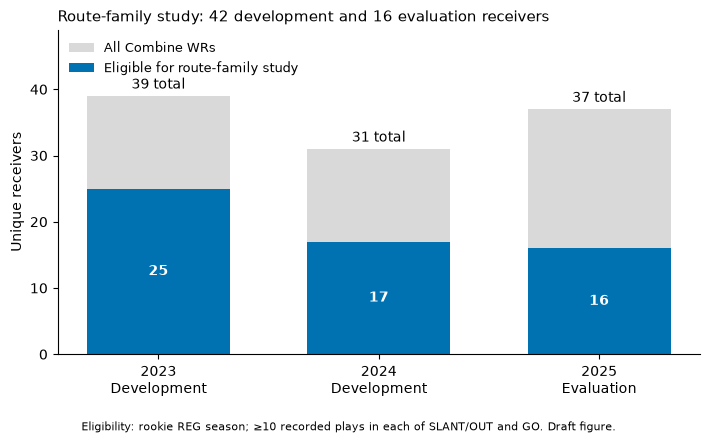

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
x = list(range(len(support)))
ax.bar(x, support.combine_WRs, width=.65, color='#D9D9D9', label='All Combine WRs')
ax.bar(x, support.eligible_WRs, width=.65, color='#0072B2', label='Eligible for route-family study')
for i, row in enumerate(support.itertuples(index=False)):
    ax.text(i, row.eligible_WRs / 2, str(row.eligible_WRs), ha='center', va='center', color='white', fontweight='bold')
    ax.text(i, row.combine_WRs + .6, f'{row.combine_WRs} total', ha='center', va='bottom', fontsize=10)
ax.set_xticks(x, [f'{year}\n' + ('Development' if year < 2025 else 'Evaluation') for year in support.draft_year])
ax.set_ylabel('Unique receivers')
development_n = int(support.loc[support.draft_year.isin([2023,2024]), 'eligible_WRs'].sum())
evaluation_n = int(support.loc[support.draft_year == 2025, 'eligible_WRs'].sum())
ax.set_title(f'Route-family study: {development_n} development and {evaluation_n} evaluation receivers', loc='left', fontsize=11)
ax.set_ylim(0, max(support.combine_WRs) + 10)
ax.spines[['top','right']].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc='upper left')
fig.text(.12, .01, 'Eligibility: rookie REG season; ≥10 recorded plays in each of SLANT/OUT and GO. Draft figure.', fontsize=8)
fig.tight_layout(rect=[0,.05,1,1])
out = Path('reports/figures')
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / 'study3_support.png', dpi=200, bbox_inches='tight')
plt.show()

## Frozen outcome measurement screen

The screen asks whether a receiver's SLANT/OUT-minus-GO separation contrast repeats
across alternating rookie games. It does not test Combine TURN against separation.
Eligibility is ≥10 plays in each family; diagnostic halves require ≥3 in each family.

The conventional weighted model uses player intercepts, separate route/down/coverage/
alignment terms, yards-to-go, motion, cushion/missingness and conventional-measurable
family interactions. Every athlete/family gets equal total weight. Player scaling uses
unique development-class WRs; no 2025 outcomes enter the fit or diagnostic.

Subtracting this baseline shares estimated adjustments across halves, so adjusted
reliability is descriptive. The frozen gate requires ≥25 diagnostic athletes and
Spearman–Brown point reliability ≥0.40. Wide intervals remain relevant to interpretation.

In [5]:
import numpy as np
import statsmodels.api as sm
import json
SEED = 20261109
CONVENTIONAL = ['weight_z', 'height_z', 'forty_z', 'pick_z', 'udfa', 'forty_missing']
CATEGORICAL = ['route_ran', 'down', 'team_coverage_man_zone', 'receiver_alignment']

def paired_reliability(x, y, n_boot=10000, seed=SEED):
    x, y = np.asarray(x, float), np.asarray(y, float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    n = len(x)
    if n < 4 or np.std(x) == 0 or np.std(y) == 0:
        return dict(n=n, r=None, r_lo=None, r_hi=None, SB=None,
                    SB_lo=None, SB_hi=None, valid_bootstraps=0)
    r = float(np.corrcoef(x, y)[0, 1])
    rng = np.random.default_rng(seed)
    draws = rng.integers(n, size=(n_boot, n))
    a, b = x[draws], y[draws]
    a -= a.mean(axis=1, keepdims=True)
    b -= b.mean(axis=1, keepdims=True)
    denom = np.sqrt((a*a).sum(axis=1) * (b*b).sum(axis=1))
    rs = np.divide((a*b).sum(axis=1), denom,
                   out=np.full(n_boot, np.nan), where=denom > 0)
    rs = rs[np.isfinite(rs)]
    lo, hi = np.quantile(rs, [0.025, 0.975])
    # Retain negative estimates; do not turn noise into positive reliability.
    sb = lambda v: float(2*v/(1+v)) if v > -1 else None
    return dict(n=n, r=r, r_lo=float(lo), r_hi=float(hi), SB=sb(r),
                SB_lo=sb(lo), SB_hi=sb(hi), valid_bootstraps=len(rs))


def independent_columns(design, weights):
    """Keep columns in declared order using a scale-aware orthogonal rank rule."""
    a = design.to_numpy(float) * np.sqrt(np.asarray(weights))[:, None]
    basis, keep, dropped = [], [], []
    for j, name in enumerate(design.columns):
        v = a[:, j].copy()
        scale = np.linalg.norm(v)
        if scale:
            for _ in range(2):
                for q in basis:
                    v -= q * np.dot(q, v)
        norm = np.linalg.norm(v)
        if norm <= 1e-10 * max(scale, 1):
            dropped.append(name)
        else:
            keep.append(name)
            basis.append(v/norm)
    return design[keep], dropped


def preprocess_development(dev, player_table, include_turn=True):
    reference = player_table[(player_table.combine_position=='WR')
                             & player_table.draft_year.isin([2023,2024])].copy()
    median_forty = float(reference.forty.median())
    scalers = {}
    for name, d in [('reference', reference), ('development', dev)]:
        d['udfa'] = d.draft_overall_pick.isna().astype(int)
        d['pick'] = d.draft_overall_pick.fillna(260)
        d['forty_missing'] = d.forty.isna().astype(int)
        d['forty'] = d.forty.fillna(median_forty)
        d['weight'], d['height'] = d.combine_weight, d.combine_height
        features = ['weight', 'height', 'forty', 'pick'] + (['TURN'] if include_turn else [])
        for feature in features:
            if name=='reference':
                scalers[feature] = dict(mean=float(d[feature].mean()), sd=float(d[feature].std(ddof=1)))
            s = scalers[feature]
            if not np.isfinite(s['sd']) or s['sd']<=0:
                raise ValueError(f'Invalid training player SD: {feature}')
            d[f'{feature}_z'] = (d[feature]-s['mean'])/s['sd']
    missing = dict(cushion=int(dev.cushion.isna().sum()),
                   motion=int(dev.in_motion_at_ball_snap.isna().sum()),
                   coverage=int(dev.team_coverage_man_zone.isna().sum()),
                   alignment=int(dev.receiver_alignment.isna().sum()))
    cushion_median = float(dev.cushion.median())
    if not np.isfinite(cushion_median):
        raise ValueError('No observed development cushions')
    dev['cushion_missing'] = dev.cushion.isna().astype(int)
    dev['cushion_f'] = dev.cushion.fillna(cushion_median)
    dev['motion'] = dev.in_motion_at_ball_snap.fillna(False).astype(int)
    for category in CATEGORICAL:
        dev[category] = dev[category].fillna('UNK').astype(str)
    levels = {category: sorted(dev[category].unique().tolist()) for category in CATEGORICAL}
    metadata = dict(reference_players=len(reference), reference_classes=[2023,2024],
                    median_forty=median_forty, cushion_median=cushion_median,
                    player_scalers=scalers, categories=levels, development_missing=missing,
                    evaluation_unknown_rule='Unseen levels map to UNK if present, otherwise first training level')
    return dev, metadata


def baseline_design(dev, metadata):
    x = pd.DataFrame({'Intercept': np.ones(len(dev))}, index=dev.index)
    ids = sorted(dev.nfl_id.unique())
    for pid in ids[1:]:
        x[f'player_{pid}'] = (dev.nfl_id==pid).astype(float)
    for cat in CATEGORICAL:
        for level in metadata['categories'][cat][1:]:
            x[f'{cat}={level}'] = (dev[cat]==level).astype(float)
    for feature in ['yards_to_go', 'motion', 'cushion_f', 'cushion_missing']:
        x[feature] = dev[feature].astype(float)
    for feature in CONVENTIONAL:
        x[f'{feature}:BREAK'] = dev[feature] * dev.BREAK
    weights = 1/dev.groupby(['nfl_id','BREAK']).nfl_id.transform('size')
    x, dropped = independent_columns(x, weights)
    return x, weights, dropped


def measurement_screen(dev, x, weights):
    fit = sm.WLS(dev.separation_at_pass_forward, x, weights=weights).fit()
    dev = dev.copy()
    # Player intercepts cancel in the family difference. Subtract all other baseline
    # components, including conventional interactions, as specified by the screen.
    component = [name for name in x if name!='Intercept' and not name.startswith('player_')]
    dev['adjusted'] = dev.separation_at_pass_forward - x[component].dot(fit.params[component])
    game_order = dev[['nfl_id','game_id']].drop_duplicates().sort_values(['nfl_id','game_id'])
    game_order['half'] = game_order.groupby('nfl_id').cumcount()%2
    dev = dev.merge(game_order, validate='many_to_one')
    family = dev.groupby(['nfl_id','half','BREAK']).agg(
        n=('nfl_id','size'), raw=('separation_at_pass_forward','mean'), adjusted=('adjusted','mean'))
    counts = family.n.unstack(['half','BREAK']).reindex(columns=pd.MultiIndex.from_product([[0,1],[0,1]]))
    ids = counts.index[(counts.fillna(0)>=3).all(axis=1)]
    contrasts = pd.DataFrame(index=ids)
    rows = []
    for outcome in ['raw','adjusted']:
        cells = family[outcome].unstack(['half','BREAK'])
        for half in [0,1]:
            contrasts[f'{outcome}_{half}'] = cells.loc[ids, (half,1)]-cells.loc[ids, (half,0)]
        rows.append(dict(contrast=outcome, **paired_reliability(
            contrasts[f'{outcome}_0'], contrasts[f'{outcome}_1'])))
    adjusted = rows[1]
    passes = (len(ids)>=25 and adjusted['SB'] is not None and adjusted['SB']>=0.40)
    return rows, contrasts.reset_index(), fit, passes


def plot_screen(contrasts, rows, target):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1,2,figsize=(9,4.3),layout='constrained')
    for ax, row, color in zip(axes,rows,['#0072B2','#D55E00']):
        kind = row['contrast']
        a, b = contrasts[f'{kind}_0'], contrasts[f'{kind}_1']
        ax.scatter(a,b,color=color,alpha=.75,s=28)
        limits = [min(a.min(),b.min())-.15, max(a.max(),b.max())+.15]
        ax.plot(limits,limits,color='#777777',lw=.8,ls='--')
        ax.axhline(0,color='#BBBBBB',lw=.6); ax.axvline(0,color='#BBBBBB',lw=.6)
        ax.set(xlim=limits,ylim=limits,xlabel='Alternating games: half A (yards)',
               ylabel='Alternating games: half B (yards)')
        if row['r'] is not None:
            ax.set_title(f"{kind.capitalize()} contrast · n={row['n']}\n"
                         f"r={row['r']:.2f} [{row['r_lo']:.2f}, {row['r_hi']:.2f}] · SB={row['SB']:.2f}",fontsize=10)
    fig.suptitle('Does BREAK-minus-GO separation repeat across rookie games?',fontsize=13)
    fig.savefig(target,dpi=200)
    plt.close(fig)


,contrast,n,r,r_lo,r_hi,SB,SB_lo,SB_hi,valid_bootstraps
0,raw,41,0.301364,0.031950,0.559579,0.463151,0.061922,0.717603,10000
1,adjusted,41,0.173796,-0.113716,0.434928,0.296127,-0.256614,0.606202,10000


Measurement gate: FAIL — stop primary route-performance claim


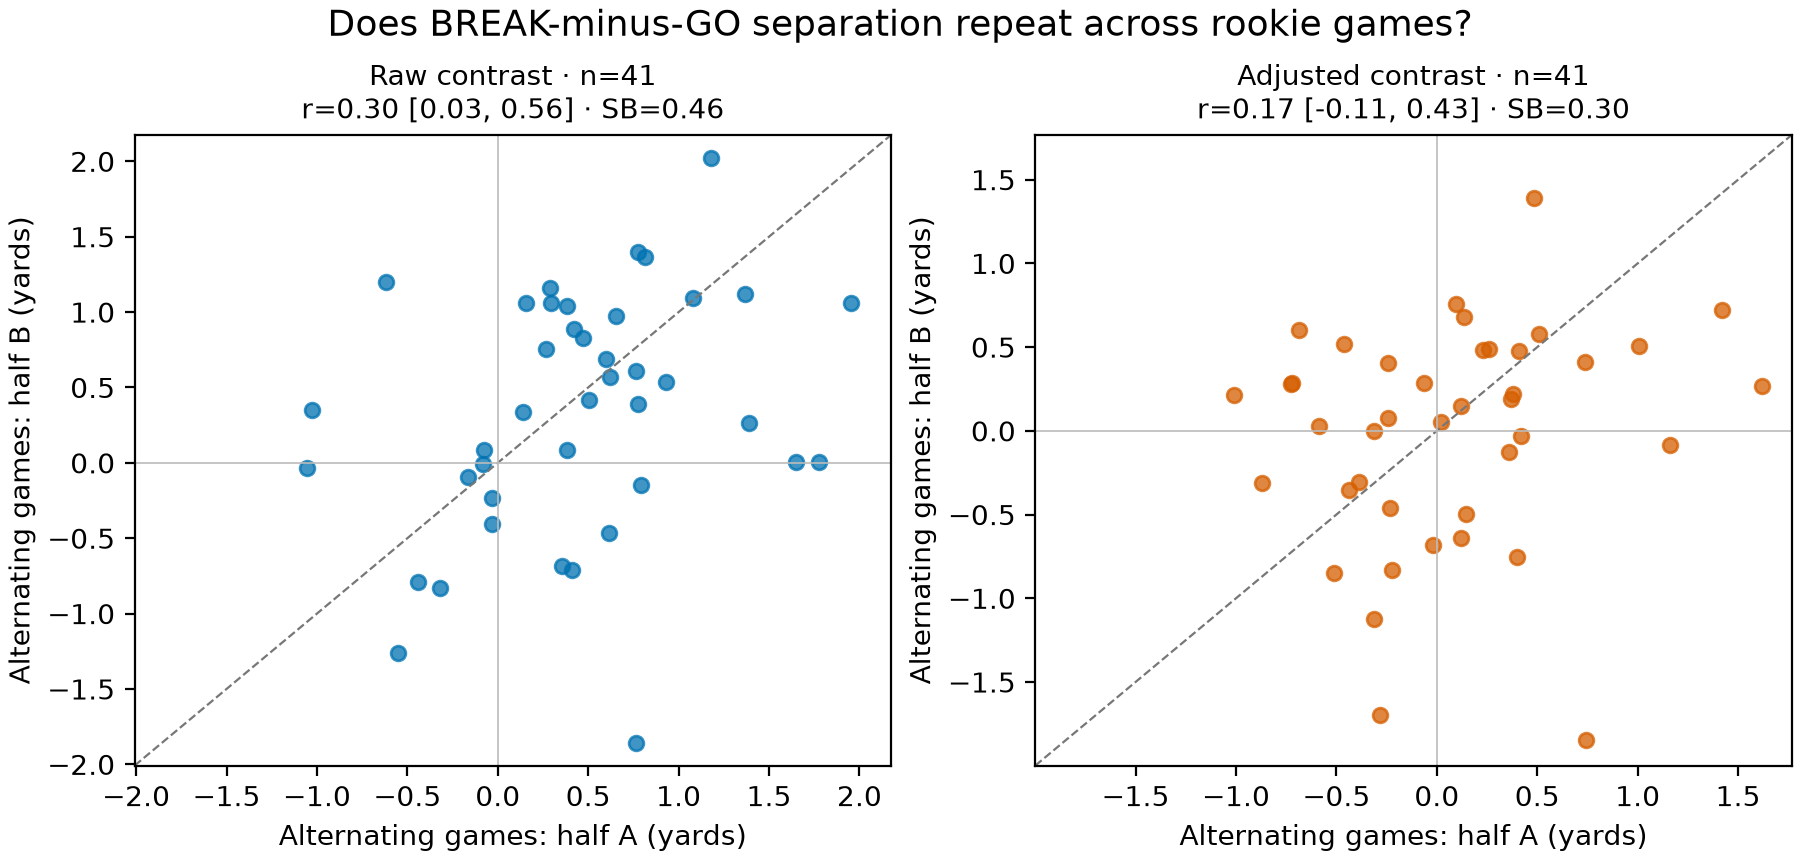

In [6]:
# Materialise only 2023–24 candidate WR outcomes and small conventional reference.
reference = con.sql("""SELECT c.*,p.draft_overall_pick FROM combine_results c
    JOIN players p USING(nfl_id)
    WHERE c.combine_position='WR' AND c.draft_year IN (2023,2024)""").df()
dev = con.sql("""SELECT pp.*,c.draft_year,c.combine_position,c.forty,
    c.combine_weight,c.combine_height,p.draft_overall_pick
    FROM player_play pp JOIN games g USING(game_id)
    JOIN combine_results c USING(nfl_id) JOIN players p USING(nfl_id)
    WHERE c.combine_position='WR' AND c.draft_year IN (2023,2024)
      AND g.season_type='REG' AND g.season=c.draft_year
      AND pp.play_nullified_by_penalty='N' AND pp.route_ran IN ('SLANT','OUT','GO')
      AND pp.separation_at_pass_forward IS NOT NULL""").df()
dev['BREAK'] = (dev.route_ran!='GO').astype(int)
counts = dev.groupby(['nfl_id','BREAK']).size().unstack(fill_value=0)
eligible = counts.index[(counts[0]>=10)&(counts[1]>=10)]
dev = dev[dev.nfl_id.isin(eligible)].dropna(subset=[
    'down','yards_to_go','combine_weight','combine_height']).copy()
counts = dev.groupby(['nfl_id','BREAK']).size().unstack(fill_value=0)
eligible = counts.index[(counts[0]>=10)&(counts[1]>=10)]
dev = dev[dev.nfl_id.isin(eligible)].copy()
assert dev.draft_year.isin([2023,2024]).all()
assert dev.nfl_id.nunique() >= 35
dev, metadata = preprocess_development(dev,reference,include_turn=False)
x, weights, dropped = baseline_design(dev,metadata)
rows, contrasts, baseline, passes = measurement_screen(dev,x,weights)
display(pd.DataFrame(rows))
summary = {'development_players':int(dev.nfl_id.nunique()),'development_plays':len(dev),
    'design_rank':x.shape[1],'dropped_columns':dropped,'diagnostic':rows,
    'screen_passes':bool(passes),'primary_TURN_association_fitted':False,
    'evaluation_outcomes_opened':False}
print('Measurement gate:', 'PASS' if passes else 'FAIL — stop primary route-performance claim')
Path('reports').mkdir(exist_ok=True)
Path('reports/notebook_measurement.json').write_text(json.dumps(summary,indent=2,allow_nan=False))
plot_screen(contrasts,rows,out/'study3_measurement.png')
from IPython.display import Image, display
display(Image(filename=str(out/'study3_measurement.png')))
con.close()

## Interpretation and remaining work

The local run gives 41 diagnostic development receivers. Adjusted correlation is
approximately 0.17 (95% bootstrap interval −0.11 to 0.43); Spearman–Brown is approximately
0.30, below the frozen 0.40 gate. The interval is wide. This failure limits the route-family
performance claim; it does not establish that Combine movement has no value.

The project now follows the planned evidence-map narrative: distinguish reproducible
movement, transfer into games and evidence of additional performance prediction.
Historical model audits still show no Holm-significant added associations, but held-out
prediction and the small 3-cone sensitivity must be completed before final claims.
Full feature rebuilding, audit integration, final figures and clean Kaggle execution remain
pending. This notebook is not ready for publication or submission.